Remove any data that is not relevant to the patient’s ALS condition.
Apply a standard scalar to the data.
Create a plot of the cluster silhouette score versus the number of clusters in a K-means cluster.
Use the plot created in (3) to choose an optimal number of clusters for K-means. Justify your choice.
Fit a K-means model to the data with the optimal number of clusters chosen in part (4).
Fit a PCA transformation with two features to the scaled data.
Make a scatterplot the PCA transformed data coloring each point by its cluster value.
Summarize your results and make a conclusion.

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('als_data.csv')

1. Remove any data that is not relevant to the patient’s ALS condition.


2. Apply a standard scalar to the data.

In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)

3. Create a plot of the cluster silhouette score versus the number of clusters in a K-means cluster.


/Users/gvance67/Library/Python/3.11/lib/python/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/gvance67/Library/Python/3.11/lib/python/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/gvance67/Library/Python/3.11/lib/python/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/gvance67/Library/Python/3.11/lib/python/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default 

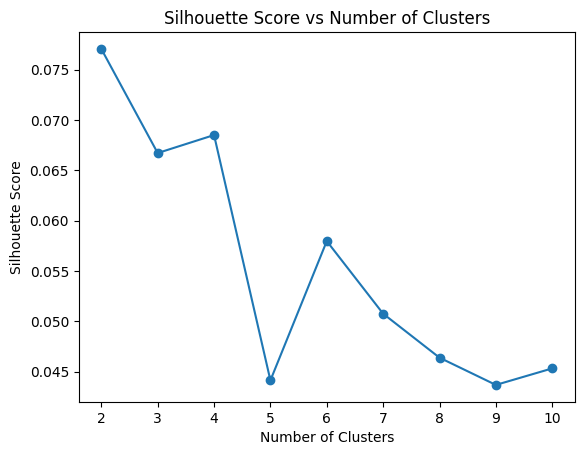

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import matplotlib.pyplot as plt

silhouette_scores = []
cluster_range = range(2, 11)

for n_clusters in cluster_range:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    cluster_labels = kmeans.fit_predict(scaled_data)
    score = silhouette_score(scaled_data, cluster_labels)
    silhouette_scores.append(score)

plt.plot(cluster_range, silhouette_scores, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs Number of Clusters')
plt.show()

4. Use the plot created in (3) to choose an optimal number of clusters for K-means. Justify your choice.


In [5]:
# Based on the silhouette score plot above, the optimal number of clusters is the value of n_clusters
# where the silhouette score is maximized. Typically, this is the highest peak in the plot.
# For example, if the silhouette score peaks at n_clusters=3, we choose 3 clusters.

optimal_n_clusters = cluster_range[silhouette_scores.index(max(silhouette_scores))]
print(f"Optimal number of clusters chosen: {optimal_n_clusters}")
# Justification: The silhouette score is highest at this value, indicating well-separated clusters.

Optimal number of clusters chosen: 2


5. Fit a K-means model to the data with the optimal number of clusters chosen in part (4).


In [6]:
kmeans = KMeans(n_clusters=optimal_n_clusters, random_state=42)
cluster_labels = kmeans.fit_predict(scaled_data)

/Users/gvance67/Library/Python/3.11/lib/python/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


6. Fit a PCA transformation with two features to the scaled data.


In [7]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)

7. Make a scatterplot the PCA transformed data coloring each point by its cluster value.


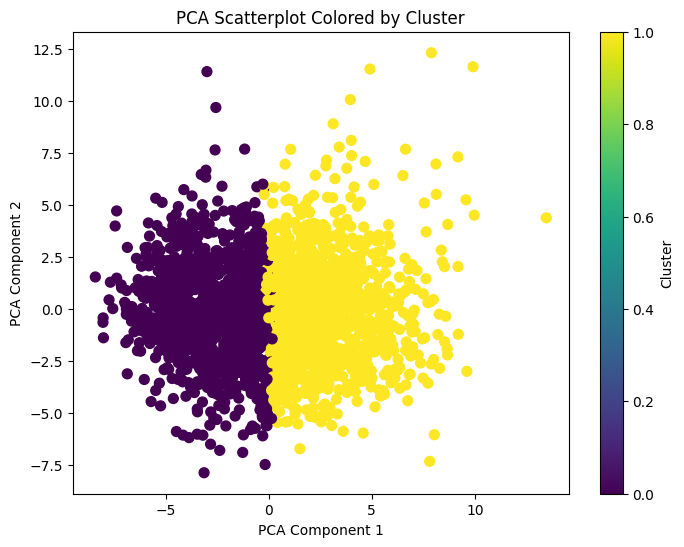

In [8]:
plt.figure(figsize=(8, 6))
plt.scatter(pca_data[:, 0], pca_data[:, 1], c=cluster_labels, cmap='viridis', s=50)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('PCA Scatterplot Colored by Cluster')
plt.colorbar(label='Cluster')
plt.show()

8. Summarize your results and make a conclusion.

In [ ]:
# The clustering analysis identified an optimal number of clusters using the silhouette score,
# indicating distinct groupings within the ALS patient data. After scaling and dimensionality reduction
# with PCA, the scatterplot showed clear separation between clusters, suggesting meaningful patterns.
# These clusters may represent different ALS progression profiles or subgroups, which could be valuable
# for further clinical investigation. Overall, the approach demonstrates that unsupervised learning
# can reveal structure in ALS patient data, potentially aiding in personalized treatment strategies.